# Diferenciação numérica e automática
**Felipe M. Figueira e Lucas Carvalhosa Lago · Computação Científica · 01/12/2026**

Execute as células em ordem em Python com NumPy, Matplotlib, mpmath e JAX/JAXLIB para CPU; a última célula (D1) usa também PyTorch, e a versão para CPU basta. A comparação completa em C3 requer JAX em 64 bits. A semente em C2 é 42. As figuras são salvas na pasta local `figuras_seminario` em PNG (300 dpi) e PDF vetorial, com a paleta `PALETA` definida abaixo; são essas as figuras usadas no relatório. A letra $u$ denota o arredondamento unitário ($2^{-53}$); $\varepsilon$ é a unidade dual ($\varepsilon^2 = 0$) e $\eta = 2u = 2^{-52}$ é o espaçamento entre 1 e o próximo `float64`. Os tempos medidos dependem da máquina: a primeira célula registra o processador usado.

In [1]:
from pathlib import Path
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import mpmath as mp

pasta_figuras = Path("figuras_seminario")
pasta_figuras.mkdir(exist_ok=True)

# Estilo gráfico padronizado para o relatório, o guia e os slides do seminário.
PALETA = {
    "azul": "#1B365D",
    "ocre": "#C87A28",
    "petroleo": "#0E6B74",
    "bordo": "#8C2D3C",
    "ardosia": "#334155",
}
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#475569",
    "grid.color": "#CBD5E1",
    "grid.alpha": 0.45,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "legend.edgecolor": "#CBD5E1",
})
BORDA = "#1E293B"  # contorno das barras


def exportar(figura, nome):
    """Exporta a figura em PNG (300 dpi) e PDF vetorial."""
    figura.savefig(pasta_figuras / f"{nome}.png", dpi=300, bbox_inches="tight", facecolor="white")
    figura.savefig(pasta_figuras / f"{nome}.pdf", bbox_inches="tight", facecolor="white")


def virgula(x, casas=3):
    """Número com vírgula decimal, como no texto do relatório."""
    return f"{x:.{casas}f}".replace(".", ",")


def cientifico(x, casas=2):
    """Notação científica com vírgula decimal, em mathtext."""
    mantissa, expoente = f"{x:.{casas}e}".split("e")
    return rf"${mantissa.replace('.', '{,}')}\times 10^{{{int(expoente)}}}$"


def processador():
    """Nome do processador (Linux: /proc/cpuinfo; outros sistemas: platform)."""
    try:
        for linha in Path("/proc/cpuinfo").read_text().splitlines():
            if linha.startswith("model name"):
                return linha.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or "desconhecido"


print(f"Python {platform.python_version()} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__} | mpmath {mp.__version__}")
print(f"Processador: {processador()}")

Python 3.13.18 | NumPy 2.4.6 | Matplotlib 3.10.0 | mpmath 1.3.0
Processador: Intel(R) Xeon(R) CPU @ 2.20GHz


## B1 — Classe `Dual` e funções elementares

In [2]:
import numpy as np
from numbers import Real


def real_finito(x, nome):
    """Valida que x é um número real finito, rejeitando booleanos, complexos, NaN e inf."""
    if isinstance(x, bool) or not isinstance(x, Real):
        raise TypeError(f"{nome} deve ser um número real.")
    x = float(x)
    if not np.isfinite(x):
        raise ValueError(f"{nome} deve ser finito.")
    return x


class Dual:
    """Número dual a + b*eps (eps^2 = 0): parte real escalar e derivada escalar ou vetorial."""
    __array_priority__ = 1000  # Garante precedência sobre escalares NumPy nas operações.

    def __init__(self, val, der=0.0):
        # Armazena o valor real (val) e copia a derivada (der) como array float (0D ou 1D).
        self.val = real_finito(val, "val")
        der = np.asarray(der)
        if der.ndim > 1 or der.dtype.kind not in "iuf":
            raise TypeError("der deve ser um escalar ou vetor real.")
        self.der = np.array(der, dtype=float, copy=True)
        if not np.all(np.isfinite(self.der)):
            raise ValueError("der deve conter apenas valores finitos.")

    @staticmethod
    def converter(x):
        """Converte uma constante real c em Dual(c, 0.0); mantém objetos Dual inalterados."""
        return x if isinstance(x, Dual) else Dual(x)

    def __add__(self, other):
        # Soma componente a componente: (a + b*eps) + (c + d*eps) = (a + c) + (b + d)*eps.
        other = Dual.converter(other)
        return Dual(self.val + other.val, self.der + other.der)

    __radd__ = __add__  # Soma comutativa quando a constante está à esquerda.

    def __neg__(self):
        # Negação: -(a + b*eps) = -a - b*eps.
        return Dual(-self.val, -self.der)

    def __sub__(self, other):
        # Subtração implementada como soma com o oposto.
        return self + (-Dual.converter(other))

    def __rsub__(self, other):
        # Subtração refletida (c - x), preservando a ordem dos operandos.
        return Dual.converter(other) - self

    def __mul__(self, other):
        # Regra do produto (eps^2 = 0): (a + b*eps)(c + d*eps) = ac + (ad + bc)*eps.
        other = Dual.converter(other)
        return Dual(self.val * other.val,
                    self.der * other.val + self.val * other.der)

    __rmul__ = __mul__  # Multiplicação comutativa quando a constante está à esquerda.

    def __truediv__(self, other):
        # Regra do quociente sem formar explicitamente c^2: (a/c, (a' - (a/c)*c') / c).
        other = Dual.converter(other)
        if other.val == 0:
            raise ZeroDivisionError("Divisão por Dual com valor zero.")
        valor = self.val / other.val
        return Dual(valor, (self.der - valor * other.der) / other.val)

    def __rtruediv__(self, other):
        # Divisão refletida (c / x), preservando a ordem dos operandos.
        return Dual.converter(other) / self

    def __pow__(self, p):
        # Regra da potência para expoente real constante p: (a^p, p * a^(p-1) * a').
        # Expoentes Dual (ex.: x**x) e __rpow__ (ex.: 2**x) não fazem parte desta classe.
        if isinstance(p, bool) or not isinstance(p, Real):
            return NotImplemented
        p = real_finito(p, "expoente")
        if p == 0:
            return Dual(1, np.zeros_like(self.der))
        if self.val == 0 and p < 0:
            raise ZeroDivisionError("Zero elevado a expoente negativo.")
        if (self.val < 0 and not p.is_integer()) or (self.val == 0 and p < 1):
            raise ValueError("Potência sem derivada real finita neste ponto.")
        return Dual(self.val**p, p * self.val**(p - 1) * self.der)

    def __abs__(self):
        # Valor absoluto: derivável fora da origem com sinal(val)*der; sinaliza erro em 0.
        if self.val == 0:
            raise ValueError("abs não é diferenciável em zero.")
        return Dual(abs(self.val), np.sign(self.val) * self.der)

    def __repr__(self):
        return f"Dual(val={self.val}, der={self.der})"


def aplicar(x, g, dg):
    """Aplica a regra da cadeia g(a + b*eps) = g(a) + g'(a)*b*eps; erros numéricos viram exceções."""
    with np.errstate(divide="raise", over="raise", invalid="raise"):
        if isinstance(x, Dual):
            return Dual(g(x.val), dg(x.val) * x.der)
        return g(x)


def exp(x):
    """Exponencial para números reais, complexos, arrays ou Dual: (e^x)' = e^x."""
    return aplicar(x, np.exp, np.exp)


def sin(x):
    """Seno para números reais, complexos, arrays ou Dual: (sin x)' = cos x."""
    return aplicar(x, np.sin, np.cos)


def cos(x):
    """Cosseno para números reais, complexos, arrays ou Dual: (cos x)' = -sin x."""
    return aplicar(x, np.cos, lambda t: -np.sin(t))


def log(x):
    """Logaritmo natural (exige argumento positivo no domínio real): (log x)' = 1/x."""
    valor = x.val if isinstance(x, Dual) else x
    if np.isrealobj(valor) and np.any(np.asarray(valor) <= 0):
        raise ValueError("log requer argumento positivo no domínio real.")
    return aplicar(x, np.log, lambda t: 1 / t)


## B2 — Derivadas e cinco funções de teste

In [3]:
def passo_valido(h):
    h = real_finito(h, "h")
    if h <= 0:
        raise ValueError("h deve ser positivo.")
    return h


def deriv_complexa(f, x, h=1e-30):
    """Requer f real no eixo real e extensão holomorfa perto de x."""
    x, h = real_finito(x, "x"), passo_valido(h)
    y = f(x + 1j * h)
    if not np.isscalar(y) or not isinstance(y, (Real, complex, np.number)):
        raise TypeError("f deve retornar um escalar numérico.")
    if not np.isfinite(y):
        raise FloatingPointError("f retornou um valor não finito.")
    resultado = np.imag(y) / h
    if not np.isfinite(resultado):
        raise FloatingPointError("Derivada complexa não finita.")
    return float(resultado)


def deriv_dual(f, x):
    resultado = Dual.converter(f(Dual(x, 1.0)))
    if resultado.der.ndim != 0:
        raise ValueError("A derivada escalar recebeu um vetor de derivadas.")
    return float(resultado.der)


def f1(x):
    return exp(x)


def f2(x):
    return log(x)


def f3(x):
    return exp(sin(x * x))


def f4(x):
    return abs(x)


def f5(x):
    A = np.array([[2, x], [1, 3]])
    return np.linalg.solve(A, np.array([1, 2]))[0]


def df1(x):
    return np.exp(x)


def df2(x):
    return 1 / x


def df3(x):
    return 2 * x * np.cos(x * x) * np.exp(np.sin(x * x))


def df4(x):
    if x == 0:
        raise ValueError("abs não é diferenciável em zero.")
    return np.sign(x)


def df5(x):
    return -9 / (6 - x)**2


ERROS_ESPERADOS = (TypeError, ValueError, ArithmeticError, np.linalg.LinAlgError)


def tentar(rotina, f, x):
    # Uma falha esperada não interrompe os demais casos.
    try:
        return f"{rotina(f, x):.10g}"
    except ERROS_ESPERADOS as exc:
        return f"{type(exc).__name__}: {exc}"


casos = [("exp", f1, df1, 1.0), ("log", f2, df2, 2.0),
         ("exp(sin(x²))", f3, df3, 0.7), ("abs", f4, df4, 0.0),
         ("solve", f5, df5, 1.0)]
for nome, f, df, x in casos:
    print(f"{nome}, x={x:g} | analítica: {tentar(lambda g, t: g(t), df, x)}")
    print(f"  complexo: {tentar(deriv_complexa, f, x)}")
    print(f"  Dual:     {tentar(deriv_dual, f, x)}")

print("\nabs fora da origem:")
for x in (-1.0, 1.0):
    print(f"x={x:+g}: exata={df4(x):+g}, complexo={deriv_complexa(f4, x):g}, "
          f"Dual={deriv_dual(f4, x):+g}")


exp, x=1 | analítica: 2.718281828
  complexo: 2.718281828
  Dual:     2.718281828
log, x=2 | analítica: 0.5
  complexo: 0.5
  Dual:     0.5
exp(sin(x²)), x=0.7 | analítica: 1.977655834
  complexo: 1.977655834
  Dual:     1.977655834
abs, x=0 | analítica: ValueError: abs não é diferenciável em zero.
  complexo: 0
  Dual:     ValueError: abs não é diferenciável em zero.
solve, x=1 | analítica: -0.36
  complexo: -0.36
  Dual:     UFuncTypeError: Cannot cast ufunc 'solve1' input 0 from dtype('O') to dtype('float64') with casting rule 'same_kind'

abs fora da origem:
x=-1: exata=-1, complexo=0, Dual=-1
x=+1: exata=+1, complexo=0, Dual=+1


`abs(x + ih)` é real: o passo complexo retorna zero, inclusive quando a derivada real vale $\pm 1$. Na origem, a derivada não existe; zero não é uma resposta válida. A classe `Dual` sinaliza esse caso explicitamente.

Em `f5`, a primeira componente é $(3-2x)/(6-x)$, portanto $f_5'(x)=-9/(6-x)^2$, para $x\ne 6$. O passo complexo funciona; a matriz com `Dual` tem `dtype=object`, não aceito pelo solver numérico do NumPy.

**Cuidados estruturais (Seções 3 e 4.3 do relatório):** (i) no passo complexo, rotinas que conjugam complexos (como `np.vdot`) invertem o sinal da parte imaginária e invalidam a derivada; (ii) a AD deriva o *programa*, não a função matemática: expressões como `sqrt(x*x)` têm derivada AD indefinida em `x = 0`, e um método iterativo de Newton dentro de `f` é derivado através das iterações, fazendo o resultado depender do critério de parada (uma questão de estabilidade, não de truncamento).

### Verificações rápidas

In [4]:
for f, df, x in [(f1, df1, 1.0), (f2, df2, 2.0), (f3, df3, 0.7)]:
    np.testing.assert_allclose(deriv_dual(f, x), df(x), rtol=1e-13)
    np.testing.assert_allclose(deriv_complexa(f, x), df(x), rtol=1e-13)
np.testing.assert_allclose(deriv_complexa(f5, 1.0), df5(1.0), rtol=1e-13)
np.testing.assert_allclose(deriv_dual(lambda x: 2 - 3/x + x**2, 2), 4.75)
np.testing.assert_allclose(deriv_dual(cos, 0.7), -np.sin(0.7))
assert deriv_dual(lambda x: 7, 2) == 0
print("Verificações de derivadas aprovadas.")


Verificações de derivadas aprovadas.


## C1 — Erro em função do passo

$$f(x)=\frac{e^x}{\cos^3x+\sin^3x},\qquad x=1{,}5.$$

Com $D_c(h)=[f(x+h)-f(x-h)]/(2h)$, usamos
$R(h)=[4D_c(h/2)-D_c(h)]/3$.
O modelo $E(h)\approx ah^p+bu/h$ prevê
$h_*=[bu/(pa)]^{1/(p+1)}$.

| Método | $p$ | $a$ | $b$ aproximado |
|---|---:|---:|---:|
| Progressiva | 1 | $\lvert f''\rvert /2$ | $2\lvert f\rvert $ |
| Centrada | 2 | $\lvert f'''\rvert /6$ | $\lvert f\rvert $ |
| Richardson | 4 | $\lvert f^{(5)}\rvert /480$ | $3\lvert f\rvert $ |

**Passo efetivo.** O passo é tomado como a diferença entre os pontos de fato avaliados, $(x+h)-x$ ou $[(x+h)-(x-h)]/2$. Assim o arredondamento de $x\pm h$, de ordem $u\lvert x\rvert\lvert f'\rvert/h$, não se soma ao termo de arredondamento e o modelo acima vale como está. Se $x+h$ arredonda para $x$, o passo efetivo é nulo e a estimativa degenera em 0.

As linhas tracejadas indicam essas estimativas, não os mínimos observados.
Na região dominada pelo arredondamento a curva é ruidosa e o mínimo da malha é um cancelamento fortuito; por isso comparamos o erro previsto $E(h_*)$ com a **mediana dos 7 pontos da malha mais próximos de $h_*$**.
No passo complexo, $E(h)=O(h^2)+O(u)$: **não há ótimo interior
no modelo usual**. A linha pontilhada marca o início estimado do patamar,
quando $|f'''|h^2/6\approx u\lvert f'\rvert $. Passos extremos ainda podem
sofrer subfluxo. A referência e as derivadas do modelo usam 60 casas via
`mpmath`; a implementação `Dual` continua independente dessa biblioteca.

Progressiva    : h previsto=1.17e-08; erro previsto=1.71e-07; mediana perto de h*=9.75e-08; menor erro da malha=9.69e-09 em h=1.14e-08
Centrada       : h previsto=2.98e-06; erro previsto=2.52e-10; mediana perto de h*=9.50e-11; menor erro da malha=2.04e-11 em h=2.22e-06
Richardson     : h previsto=6.39e-04; erro previsto=2.94e-12; mediana perto de h*=3.30e-12; menor erro da malha=2.35e-15 em h=1.26e-04
Passo complexo : h previsto=6.52e-09; erro previsto=4.02e-16; mediana perto de h*=3.12e-16; menor erro da malha=1.32e-16 em h=1.00e-20


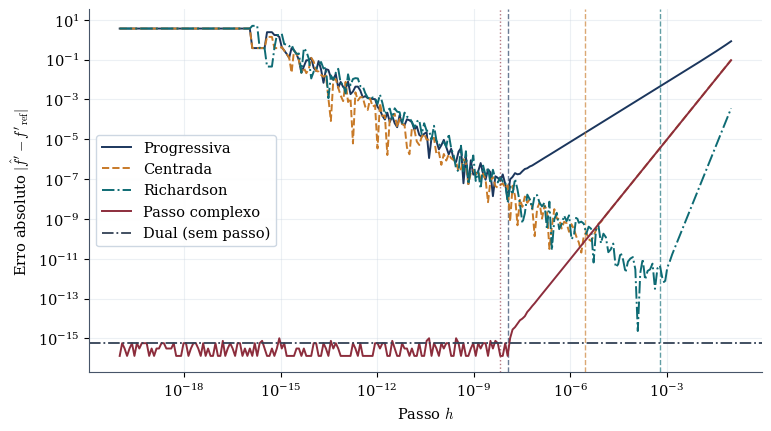

Referência: 3.622033700716326; erro Dual: 5.76e-16


In [5]:
import matplotlib.pyplot as plt
import mpmath as mp


def f_experimento(x):
    return exp(x) / (cos(x)**3 + sin(x)**3)


def progressiva(f, x, h):
    passo = (x + h) - x                 # passo efetivo: o que de fato foi somado a x
    if passo == 0:
        return 0.0                      # x + h == x: numerador nulo
    return (f(x + passo) - f(x)) / passo


def centrada(f, x, h):
    xp, xm = x + h, x - h
    if xp == xm:
        return 0.0
    return (f(xp) - f(xm)) / (xp - xm)  # divide pela distância efetiva entre os pontos


def richardson(f, x, h):
    return (4 * centrada(f, x, h/2) - centrada(f, x, h)) / 3


x0, u = 1.5, np.finfo(float).eps / 2
hs = np.logspace(-20, -1, 250)
metodos = {"Progressiva": progressiva, "Centrada": centrada,
           "Richardson": richardson, "Passo complexo": deriv_complexa}
estilo = {"Progressiva": (PALETA["azul"], "-"), "Centrada": (PALETA["ocre"], "--"),
          "Richardson": (PALETA["petroleo"], "-."), "Passo complexo": (PALETA["bordo"], "-")}

with mp.workdps(60):
    fm = lambda t: mp.exp(t) / (mp.cos(t)**3 + mp.sin(t)**3)
    t0 = mp.mpf("1.5")
    referencia = mp.diff(fm, t0)
    d2, d3, d5 = [float(abs(mp.diff(fm, t0, k))) for k in (2, 3, 5)]
    f0 = abs(float(fm(t0)))
    # A subtração em alta precisão evita falsos erros iguais a zero.
    erros = {nome: np.array([float(abs(mp.mpf(float(m(f_experimento, x0, h)))
                                       - referencia)) for h in hs])
             for nome, m in metodos.items()}
    erro_dual = float(abs(mp.mpf(deriv_dual(f_experimento, x0)) - referencia))

h_modelo = {"Progressiva": (2*f0*u / (d2/2))**0.5,
            "Centrada": (f0*u / (2*d3/6))**(1/3),
            "Richardson": (3*f0*u / (4*d5/480))**0.2}
erro_modelo = {"Progressiva": lambda h: h/2*d2 + 2*f0*u/h,
               "Centrada": lambda h: h**2/6*d3 + f0*u/h,
               "Richardson": lambda h: h**4/480*d5 + 3*f0*u/h}
h_patamar = np.sqrt(u * abs(float(referencia)) / (d3/6))


def mediana_perto(erro, h_alvo, k=3):
    """Mediana dos 2k+1 pontos da malha mais próximos de h_alvo (escala log)."""
    j = int(np.argmin(np.abs(np.log(hs) - np.log(h_alvo))))
    return float(np.median(erro[max(j - k, 0):j + k + 1]))


c1_resultados = {}
fig, ax = plt.subplots(figsize=(7.6, 4.2), constrained_layout=True)
for nome, erro in erros.items():
    cor, traco = estilo[nome]
    ax.loglog(hs, erro, color=cor, linestyle=traco, lw=1.4, label=nome)
    if nome == "Passo complexo":
        h_marca = h_patamar
        previsto = u * abs(float(referencia))           # c = 1 no modelo (14)
        observado = float(np.median(erro[hs <= h_patamar / 10]))
    else:
        h_marca = h_modelo[nome]
        previsto = erro_modelo[nome](h_marca)
        observado = mediana_perto(erro, h_marca)
    ax.axvline(h_marca, color=cor, alpha=0.65, lw=1.0,
               linestyle=":" if nome == "Passo complexo" else "--")
    c1_resultados[nome] = (h_marca, previsto, observado, float(erro.min()), float(hs[erro.argmin()]))
    print(f"{nome:15s}: h previsto={h_marca:.2e}; erro previsto={previsto:.2e}; "
          f"mediana perto de h*={observado:.2e}; menor erro da malha={erro.min():.2e} em h={hs[erro.argmin()]:.2e}")
ax.axhline(erro_dual, color=PALETA["ardosia"], linestyle="-.", lw=1.3, label="Dual (sem passo)")
ax.set(xlabel=r"Passo $h$", ylabel=r"Erro absoluto $|\hat{f}' - f'_{\mathrm{ref}}|$")
ax.grid(True, which="major", alpha=0.35)
ax.legend(loc="center left", framealpha=0.95)
exportar(fig, "c1")
plt.show()
print(f"Referência: {float(referencia):.16g}; erro Dual: {erro_dual:.2e}")

## C1b — Segunda derivada com um passo complexo (A3)
Para $f(x)=e^x$, a fórmula $2[f(x)-\operatorname{Re} f(x+\mathrm{i}h)]/h^2$ tem erro relativo modelado por $h^2/12+4u/h^2$. Daí $h_*=(48u)^{1/4}$ e um erro da ordem de $\sqrt{u}$. Variamos a precisão, mantemos as operações em seus respectivos tipos e medimos a mediana do erro relativo em 65 abscissas de $[0,1]$. A referência é obtida com 60 dígitos. A mediana reduz a influência de cancelamentos fortuitos num único ponto.

float32: h previsto=4.113e-02 | h na malha=3.500e-02 | erro mediano mínimo=1.126e-04
float64: h previsto=2.702e-04 | h na malha=2.141e-04 | erro mediano mínimo=1.761e-09
Razão entre os passos observados: 163.5; prevista (u32/u64)^(1/4) = 152.2; fator entre pontos vizinhos da malha: 1.117


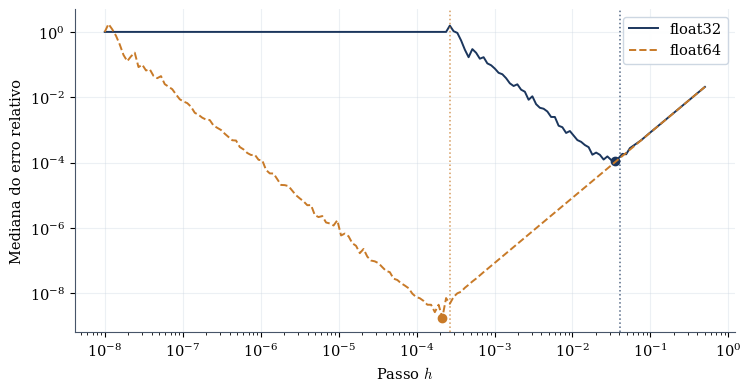

In [6]:
hs_a3 = np.geomspace(1e-8, 0.5, 161)
xs_a3 = np.linspace(0, 1, 65)  # Pontos exatamente representáveis em ambas as precisões.
with mp.workdps(60):
    ref_a3 = np.array([float(mp.exp(float(x))) for x in xs_a3])
fig, ax = plt.subplots(figsize=(7.4, 3.8), constrained_layout=True)
a3_resultados = {}
estilo_a3 = {"float32": (PALETA["azul"], "-"), "float64": (PALETA["ocre"], "--")}
for tipo, complexo in [(np.float32, np.complex64), (np.float64, np.complex128)]:
    xs = xs_a3.astype(tipo)
    unitario = np.finfo(tipo).eps / 2
    h_teorico = float((48 * float(unitario))**0.25)
    curva = []
    for passo in hs_a3:
        h = tipo(passo)
        z = xs.astype(complexo) + complexo(1j) * h
        estimativa = tipo(2) * (np.exp(xs) - np.exp(z).real) / (h*h)
        curva.append(np.median(np.abs(estimativa.astype(float) - ref_a3) / ref_a3))
    curva = np.asarray(curva)
    j = int(np.argmin(curva))
    a3_resultados[tipo.__name__] = [float(unitario), h_teorico, float(hs_a3[j]), float(curva[j])]
    cor, traco = estilo_a3[tipo.__name__]
    ax.loglog(hs_a3, curva, color=cor, linestyle=traco, lw=1.4, label=tipo.__name__)
    ax.plot(hs_a3[j], curva[j], "o", color=cor, ms=6)
    ax.axvline(h_teorico, color=cor, ls=":", lw=1.1, alpha=0.75)
    print(f"{tipo.__name__}: h previsto={h_teorico:.3e} | h na malha={hs_a3[j]:.3e} | erro mediano mínimo={curva[j]:.3e}")
razao = a3_resultados["float32"][2] / a3_resultados["float64"][2]
print(f"Razão entre os passos observados: {razao:.1f}; prevista (u32/u64)^(1/4) = {2**(29/4):.1f}; "
      f"fator entre pontos vizinhos da malha: {hs_a3[1]/hs_a3[0]:.3f}")
ax.set(xlabel=r"Passo $h$", ylabel="Mediana do erro relativo")
ax.legend(loc="upper right", framealpha=0.95); ax.grid(True, which="major", alpha=0.35)
exportar(fig, "a3"); plt.show()

## C2 — Gradiente em $\mathbb{R}^{100}$

Para $q(x)=\tfrac12x^TAx-b^Tx$, o gradiente é
$\tfrac12(A+A^T)x-b$. A matriz abaixo é simétrica, logo $\nabla q=Ax-b$.
As sementes da identidade propagam todas as componentes em uma chamada.
A diferença centrada usa, como em C1, o passo efetivo $[(x_i+\delta_i)-(x_i-\delta_i)]/2$.
O erro é relativo em norma euclidiana; o tempo é a mediana de cinco execuções
após aquecimento, incluindo a construção das perturbações e sementes.

Método           Avaliações    Erro relativo   Tempo (ms)
Centrada                200        5.827e-10       15.309
Passo complexo          100        2.440e-16       73.111
Dual vetorizada           1        3.646e-16      358.924
Dual vetorizada / passo complexo: 5x


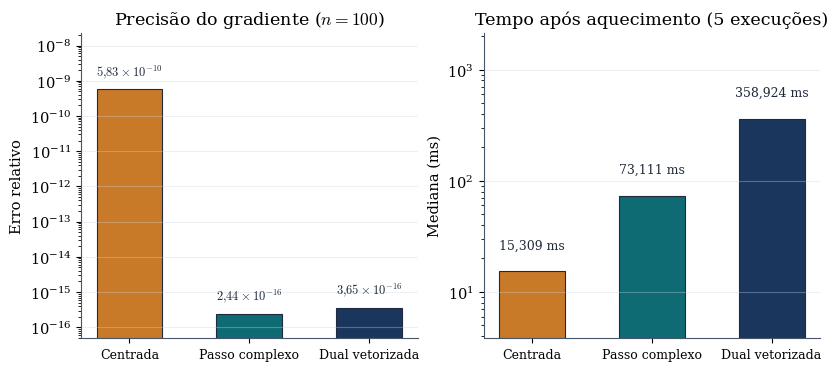

In [7]:
from time import perf_counter


def vetor_real(x):
    x = np.asarray(x)
    if x.ndim != 1 or x.size == 0 or x.dtype.kind not in "iuf":
        raise TypeError("x deve ser um vetor real não vazio.")
    x = np.array(x, dtype=float, copy=True)
    if not np.all(np.isfinite(x)):
        raise ValueError("x deve conter apenas valores finitos.")
    return x


def grad_centrada(f, x, h=np.cbrt(np.finfo(float).eps)):
    x, h = vetor_real(x), passo_valido(h)
    grad = np.empty(x.size)
    for i in range(x.size):
        delta = h * max(1, abs(x[i]))
        xp, xm = x.copy(), x.copy()
        xp[i] += delta
        xm[i] -= delta
        # Divide pela distância efetiva entre os pontos avaliados (passo efetivo).
        grad[i] = (f(xp) - f(xm)) / (xp[i] - xm[i])
    return grad


def grad_complexa(f, x, h=1e-30):
    x, h = vetor_real(x), passo_valido(h)
    grad = np.empty(x.size)
    for i in range(x.size):
        z = x.astype(complex)
        z[i] += 1j * h
        grad[i] = np.imag(f(z)) / h
    return grad


def grad_dual(f, x):
    x = vetor_real(x)
    # Cada Dual transporta um vetor de n derivadas.
    sementes = np.eye(x.size)
    xd = np.array([Dual(v, s) for v, s in zip(x, sementes)], dtype=object)
    resultado = Dual.converter(f(xd))
    return np.broadcast_to(resultado.der, x.shape).copy()


class Contador:
    def __init__(self, f):
        self.f, self.chamadas = f, 0

    def __call__(self, x):
        self.chamadas += 1
        return self.f(x)


def medir(rotina, repeticoes=5):
    rotina()  # Aquecimento fora da medição.
    tempos = []
    for _ in range(repeticoes):
        inicio = perf_counter()
        rotina()
        tempos.append(perf_counter() - inicio)
    return float(np.median(tempos))


rng = np.random.default_rng(42)
n = 100
M = rng.normal(size=(n, n))
A = M.T @ M / n + np.eye(n)
b, xg = rng.normal(size=(2, n))


def quadratica(x):
    return 0.5 * (x @ (A @ x)) - b @ x


g_exato = A @ xg - b
resultados = {}
print(f"{'Método':<16} {'Avaliações':>10} {'Erro relativo':>16} {'Tempo (ms)':>12}")
for nome, rotina, esperado in [("Centrada", grad_centrada, 200),
                              ("Passo complexo", grad_complexa, 100),
                              ("Dual vetorizada", grad_dual, 1)]:
    contada = Contador(quadratica)
    g = rotina(contada, xg)
    assert contada.chamadas == esperado
    erro = np.linalg.norm(g - g_exato) / np.linalg.norm(g_exato)
    tempo = medir(lambda: rotina(quadratica, xg))
    resultados[nome] = (g, erro, tempo)
    np.testing.assert_allclose(g, g_exato, rtol=1e-6, atol=1e-7)
    print(f"{nome:<16} {contada.chamadas:>10d} {erro:>16.3e} {tempo*1000:>12.3f}")

fig, eixos = plt.subplots(1, 2, figsize=(8.2, 3.6), constrained_layout=True)
nomes = list(resultados)
cores = [PALETA["ocre"], PALETA["petroleo"], PALETA["azul"]]
erros_c2 = [resultados[k][1] for k in nomes]
tempos_c2 = [1000*resultados[k][2] for k in nomes]
barras = eixos[0].bar(nomes, erros_c2, color=cores, edgecolor=BORDA, linewidth=0.8, width=0.55)
for barra, valor in zip(barras, erros_c2):
    eixos[0].annotate(cientifico(valor), (barra.get_x() + barra.get_width()/2, valor * 1.8),
                      ha="center", va="bottom", fontsize=9, color=BORDA)
eixos[0].set(yscale="log", ylabel="Erro relativo", title=r"Precisão do gradiente ($n = 100$)",
             ylim=(min(erros_c2) / 5, max(erros_c2) * 40))
barras = eixos[1].bar(nomes, tempos_c2, color=cores, edgecolor=BORDA, linewidth=0.8, width=0.55)
for barra, valor in zip(barras, tempos_c2):
    eixos[1].annotate(f"{virgula(valor)} ms", (barra.get_x() + barra.get_width()/2, valor * 1.5),
                      ha="center", va="bottom", fontsize=9, color=BORDA)
eixos[1].set(yscale="log", ylabel="Mediana (ms)", title="Tempo após aquecimento (5 execuções)",
             ylim=(min(tempos_c2) / 4, max(tempos_c2) * 6))
for eixo in eixos:
    eixo.grid(axis="y", alpha=0.35)
    eixo.tick_params(axis="x", labelsize=9)
print(f"Dual vetorizada / passo complexo: {resultados['Dual vetorizada'][2] / resultados['Passo complexo'][2]:.0f}x")
exportar(fig, "c2")
plt.show()

**Interpretação do custo.** Se uma avaliação escalar custa $T(n)$, as diferenças
centradas e o passo complexo usam $O(n)$ avaliações e custam $O(nT(n))$.
Dual com sementes vetoriais faz uma chamada, mas cada operação propaga $n$
derivadas: também custa $O(nT(n))$, além da memória das sementes e tangentes.
Nesta quadrática densa, $T(n)=O(n^2)$, portanto os três métodos genéricos
custam $O(n^3)$. A sobrecarga dos objetos Python pode tornar Dual mais lento.

O modo reverso para uma saída escalar precisa de uma passagem direta e uma
reversa: custo $O(T(n))$, isto é, $O(1)$ **em múltiplos do custo de avaliar a
função**, não em operações absolutas. Aqui seria $O(n^2)$, com memória para
os intermediários. O gradiente analítico também custa $O(n^2)$.

## C2b — Controle não quadrático
Acrescentamos $\sum_i\sin(x_i)$ à mesma quadrática. O gradiente de referência passa a $Ax-b+\cos(x)$, com cosseno por componente. Aplicamos exatamente os mesmos passos às duas funções para separar truncamento e cancelamento. Na quadrática a derivada terceira é nula em cada coordenada; na função modificada ela vale $-\cos(x_i)$.

Quadrática: h na malha=1.000e+00; menor erro=3.287e-15; erro em h=1: 3.287e-15
Quadrática + senos: h na malha=3.162e-05; menor erro=1.570e-10; erro em h=1: 7.726e-02


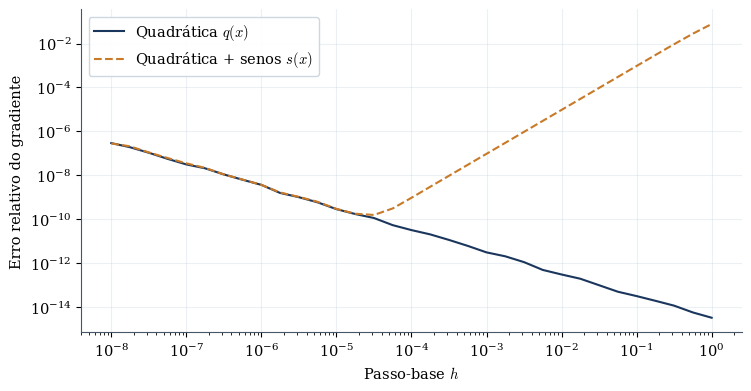

In [8]:
def suave(x):
    return quadratica(x) + np.sum(np.sin(x))
hs_multi = np.geomspace(1e-8, 1, 33)
fig, ax = plt.subplots(figsize=(7.4, 3.8), constrained_layout=True)
multi_resultados = {}
for nome, rotulo, funcao, alvo, (cor, traco) in [
        ("Quadrática", r"Quadrática $q(x)$", quadratica, g_exato, (PALETA["azul"], "-")),
        ("Quadrática + senos", r"Quadrática + senos $s(x)$", suave, g_exato + np.cos(xg), (PALETA["ocre"], "--"))]:
    curva = np.asarray([np.linalg.norm(grad_centrada(funcao, xg, h) - alvo) /
                        np.linalg.norm(alvo) for h in hs_multi])
    j = int(np.argmin(curva))
    multi_resultados[nome] = [float(hs_multi[j]), float(curva[j]), float(curva[-1])]
    ax.loglog(hs_multi, curva, color=cor, linestyle=traco, lw=1.5, label=rotulo)
    print(f"{nome}: h na malha={hs_multi[j]:.3e}; menor erro={curva[j]:.3e}; erro em h=1: {curva[-1]:.3e}")
ax.set(xlabel=r"Passo-base $h$", ylabel="Erro relativo do gradiente")
ax.grid(True, which="major", alpha=0.35); ax.legend(loc="upper left", framealpha=0.95)
exportar(fig, "c2b"); plt.show()

## C3 — Modo direto e reverso em JAX
Os quatro casos usam as mesmas entradas em `float64`. Comparamos os modos no mesmo estado de compilação e, dentro de cada modo, o uso de JIT explícito. A primeira chamada JIT inclui compilação e execução; as demais são sincronizadas com `block_until_ready()`. **Os quatro casos rodam em sequência fixa no mesmo processo**: o primeiro pode pagar custos únicos (caches de operações compiladas) que os seguintes reaproveitam, de modo que a coluna da primeira chamada não é comparável entre linhas; as medianas são. Uma medição com $n=100$ não estima um expoente assintótico. Mesmo sem JIT explícito, JAX pode compilar primitivas internamente.

**Sobre `jax.grad(jnp.abs)(0.0) = 1.0`:** em $x=0$, $|x|$ não é diferenciável (derivadas laterais $-1$ e $+1$). Enquanto o passo complexo devolve `0` (valor espúrio por violação de holomorfia) e nossa classe `Dual` lança `ValueError` (postura rigorosa), bibliotecas de aprendizado profundo como JAX adotam uma convenção pragmática de subgradiente/derivada direcional (`1.0`), evitando interromper otimizações baseadas em gradiente em pontos isolados de medida nula.

Direto sem JIT explícito   primeira: 999.559 ms | mediana: 4.359 ms | erro: 1.522e-16
Direto + JIT               primeira: 160.448 ms | mediana: 0.234 ms | erro: 1.522e-16
Reverso sem JIT explícito  primeira: 501.960 ms | mediana: 5.149 ms | erro: 1.672e-16
Reverso + JIT              primeira: 112.560 ms | mediana: 0.029 ms | erro: 1.672e-16
JAX 0.11.1, dispositivo cpu; grad(abs)(0) = 1.
Em zero, as derivadas laterais de abs divergem. O valor de JAX segue a convenção da biblioteca.
Com JIT, reverso 8.1x mais rápido que o direto (mediana).


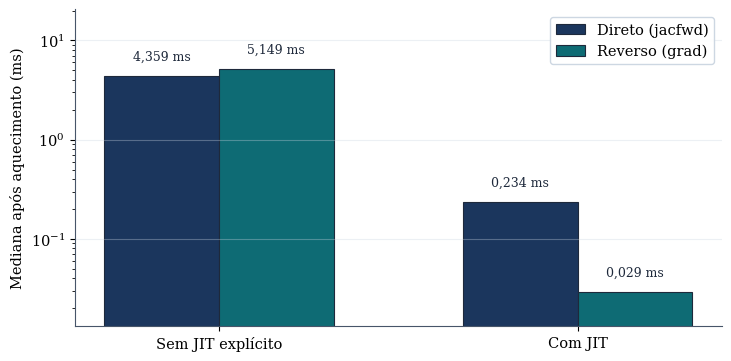

In [9]:
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)
Aj, bj, xj = (jnp.asarray(t) for t in (A, b, xg))
def qj(x, matriz, linear):
    return 0.5 * (x @ (matriz @ x)) - linear @ x

jax_resultados = {}
for nome, regra in [("Direto", jax.jacfwd), ("Reverso", jax.grad)]:
    for com_jit in (False, True):
        operador = regra(qj, argnums=0)
        if com_jit:
            operador = jax.jit(operador)
        def executar():
            return operador(xj, Aj, bj).block_until_ready()
        inicio = perf_counter()
        gj = executar()
        primeira = (perf_counter() - inicio) * 1000
        mediana = medir(executar) * 1000
        erro = np.linalg.norm(np.asarray(gj) - g_exato) / np.linalg.norm(g_exato)
        np.testing.assert_allclose(gj, g_exato, rtol=1e-12, atol=1e-12)
        rotulo = nome + (" + JIT" if com_jit else " sem JIT explícito")
        jax_resultados[rotulo] = (primeira, mediana, float(erro))
        print(f"{rotulo:25}  primeira: {primeira:.3f} ms | mediana: {mediana:.3f} ms | erro: {erro:.3e}")
abs_jax = float(jax.grad(jnp.abs)(0.0))
print(f"JAX {jax.__version__}, dispositivo {jax.devices()[0].platform}; grad(abs)(0) = {abs_jax:g}.")
print("Em zero, as derivadas laterais de abs divergem. O valor de JAX segue a convenção da biblioteca.")
fig, ax = plt.subplots(figsize=(7.2, 3.5), constrained_layout=True)
pos = np.arange(2)
for j, (modo, rotulo, cor) in enumerate([("Direto", "Direto (jacfwd)", PALETA["azul"]),
                                         ("Reverso", "Reverso (grad)", PALETA["petroleo"])]):
    tempos = [jax_resultados[modo + sufixo][1] for sufixo in (" sem JIT explícito", " + JIT")]
    barras = ax.bar(pos + (j - 0.5)*0.32, tempos, width=0.32, label=rotulo, color=cor,
                    edgecolor=BORDA, linewidth=0.8)
    for barra, valor in zip(barras, tempos):
        ax.annotate(f"{virgula(valor)} ms", (barra.get_x() + barra.get_width()/2, valor * 1.35),
                    ha="center", va="bottom", fontsize=9, color=BORDA)
todos = [v[1] for v in jax_resultados.values()]
ax.set_xticks(pos, ["Sem JIT explícito", "Com JIT"])
ax.set(yscale="log", ylabel="Mediana após aquecimento (ms)", ylim=(min(todos) / 2.2, max(todos) * 4))
ax.legend(loc="upper right", framealpha=0.95); ax.grid(axis="y", alpha=0.35)
r_jit = jax_resultados["Direto + JIT"][1] / jax_resultados["Reverso + JIT"][1]
print(f"Com JIT, reverso {r_jit:.1f}x mais rápido que o direto (mediana).")
exportar(fig, "c3"); plt.show()

## D1 — Comparação numérica com PyTorch
Repetimos o gradiente da quadrática de C2 com PyTorch em `float64`, nos modos reverso (`torch.func.grad` e o `backward()` clássico) e direto (`torch.func.jacfwd`), e comparamos com JAX e com o gradiente exato $Ax-b$. Também comparamos a derivada escalar de $\exp(\sin x^2)$ em $x=0{,}7$ com a analítica, a `Dual` e o passo complexo, e a convenção de cada biblioteca para $|x|$ em $x=0$. Não medimos tempos: C3 já trata do custo, e os tempos dependem da máquina.

Espera-se que todos fiquem no nível de $u$. As diferenças entre JAX e PyTorch vêm só da ordem das somas em ponto flutuante. Em $x=0$, as duas bibliotecas escolhem elementos diferentes do subgradiente $[-1, 1]$: as duas escolhas são válidas, e nenhuma é a derivada, que não existe.

In [10]:
import warnings
import torch
from torch.func import grad as t_grad, jacfwd as t_jacfwd

torch.set_default_dtype(torch.float64)
At, bt, xt = (torch.from_numpy(np.asarray(v, dtype=float)) for v in (A, b, xg))


def qt(x):
    return 0.5 * (x @ (At @ x)) - bt @ x


with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    gradientes = {
        "JAX reverso (grad)": np.asarray(jax.grad(qj)(xj, Aj, bj)),
        "JAX direto (jacfwd)": np.asarray(jax.jacfwd(qj)(xj, Aj, bj)),
        "PyTorch reverso (func.grad)": t_grad(qt)(xt).numpy(),
        "PyTorch reverso (backward)": None,
        "PyTorch direto (func.jacfwd)": t_jacfwd(qt)(xt).numpy(),
    }
    xa = xt.clone().requires_grad_(True)
    qt(xa).backward()
    gradientes["PyTorch reverso (backward)"] = xa.grad.numpy()

    referencia_jax = gradientes["JAX reverso (grad)"]
    print(f"PyTorch {torch.__version__} | JAX {jax.__version__} | float64 em CPU\n")
    print(f"{'Gradiente de q em R^100':<30} {'Erro rel. (exato)':>18} {'Máx. |dif.| p/ JAX grad':>24}")
    for nome, g in gradientes.items():
        erro = np.linalg.norm(g - g_exato) / np.linalg.norm(g_exato)
        print(f"{nome:<30} {erro:>18.3e} {np.max(np.abs(g - referencia_jax)):>24.3e}")

    x7 = 0.7
    exato = df3(x7)
    escalares = {
        "Dual": deriv_dual(f3, x7),
        "Passo complexo": deriv_complexa(f3, x7),
        "JAX": float(jax.grad(lambda t: jnp.exp(jnp.sin(t * t)))(x7)),
        "PyTorch": float(t_grad(lambda t: torch.exp(torch.sin(t * t)))(torch.tensor(x7))),
    }
    print(f"\nexp(sin(x²)) em x = 0,7 | analítica: {exato:.16f}")
    for nome, v in escalares.items():
        print(f"  {nome:<15} {v:.16f}  |dif.| = {abs(v - exato):.1e}")

    abs_t = float(t_grad(torch.abs)(torch.tensor(0.0)))
    print(f"\nd|x|/dx em x = 0 | JAX: {float(jax.grad(jnp.abs)(0.0)):g} | PyTorch: {abs_t:g} | "
          "passo complexo: 0 | Dual: ValueError")


PyTorch 2.14.1+cpu | JAX 0.11.1 | float64 em CPU

Gradiente de q em R^100         Erro rel. (exato)  Máx. |dif.| p/ JAX grad
JAX reverso (grad)                      1.672e-16                0.000e+00
JAX direto (jacfwd)                     1.522e-16                8.882e-16
PyTorch reverso (func.grad)             1.910e-16                8.882e-16
PyTorch reverso (backward)              1.910e-16                8.882e-16
PyTorch direto (func.jacfwd)            9.459e-17                1.332e-15

exp(sin(x²)) em x = 0,7 | analítica: 1.9776558344802251
  Dual            1.9776558344802251  |dif.| = 0.0e+00
  Passo complexo  1.9776558344802246  |dif.| = 4.4e-16
  JAX             1.9776558344802249  |dif.| = 2.2e-16
  PyTorch         1.9776558344802249  |dif.| = 2.2e-16

d|x|/dx em x = 0 | JAX: 1 | PyTorch: 0 | passo complexo: 0 | Dual: ValueError
